# Week5 : Tree Based Methods

### Objectives
This homework sheet will help reviewing the basic concepts associated with tree-based methods and provide a basic introduction to the ML workflow using real-world datasets. Please review the lectures, suggested readings, and additional resources _before_ getting started on the HW.

**Some questions in this assignment will require you to conduct independent research beyond the material covered in the recorded content.**

The following website has access to the relevant datasets from the recommended textbook: https://book.huihoo.com/introduction-to-statistical-learning/data.html

Marks Distribution

| Question      | Marks |
| ----------- | ----------- |
| 1     | 3      |
| 2     | 3     |
| 3a     | 2     |
| 3b     | 2     |
| 3c     | 5     |

# Questions

Conceptual


Q1. Draw an example (of your own invention) of a partition of two-dimensional feature space that could result from recursive binary splitting. Your example should contain at least six regions. Draw a decision tree corresponding to this partition. Be sure to label all aspects of your figures, including the regions $R_1$, $R_2$, ... , the cutpoints $t_1$ , $t_2$, ..., and so forth. Please insert your sketch below.


**Please note: You can use Microsoft word / any editor or draw the image by hand, you can upload the image / screenshot  to colab file using insert image option in text cell**


I used Microsoft Powerpoint to draw the partitions and Graphviz to generate the decision tree. Adding the dot language code I wrote for the tree.
digraph G {

  subgraph cluster_0 {
    style=filled;
    color=lightgrey;
    node [style=filled,color=white];
    R1; R2; R3; R4; R5; R6;
    label = "Regions";
  }
  
  "X1 < t1"->"X2 < t2"[label="Y"];
  "X1 < t1"->"X1 < t3"[label="N"];
  "X2 < t2"->"R1"[label="Y"];
  "X2 < t2"->"R2"[label="N"];
  "X1 < t3"->"R3"[label="Y"];
  "X1 < t3"->"X2 < t4"[label="N"];
  "X2 < t4"->"R4"[label="Y"];
  "X2 < t4"->"X1 < t5"[label="N"];
  "X1 < t5"->"R5"[label="Y"];
  "X1 < t5"->"R6"[label="N"];
}

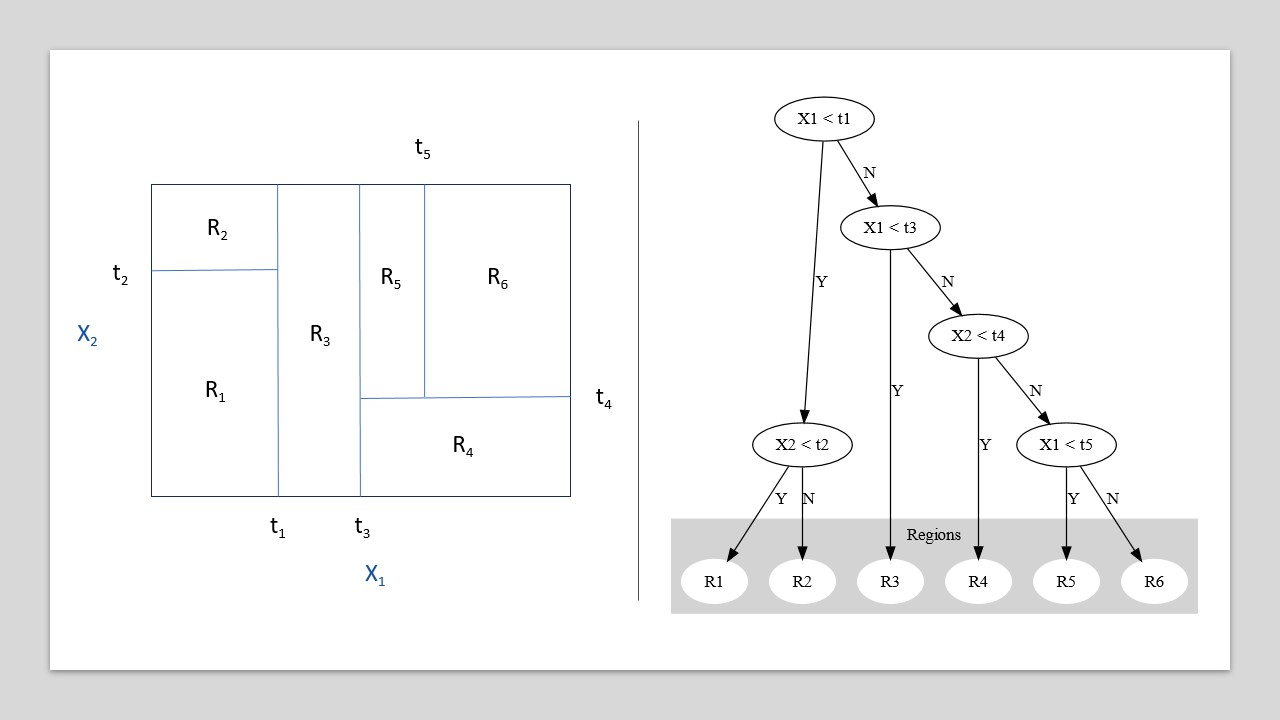

Q2. Suppose we produce ten bootstrapped samples from a data set containing red and green classes. We then apply a classification tree to each bootstrapped sample and, for a specific value of $X$, produce $10$ estimates of $P(Class is Red|X)$:

$0.1$, $0.15$, $0.2$, $0.2$, $0.55$, $0.6$, $0.6$, $0.65$, $0.7$, and $0.75$.

There are two common ways to combine these results together into a single class prediction. One is the majority vote approach , the second approach is to classify based on the average probability. In this example, what is the final classification under each of these two approaches?

Majority vote approach:
The votes shall be G, G, G, G, R, R, R, R, R, R. Red will be the predicted class.

Average probability approach:
(0.1 + 0.15 + 0.2 + 0.2 + 0.55 + 0.6 + 0.6 + 0.65 + 0.7 + 0.75) / 10 = 0.45. Green will be the predicted class.

# APPLIED

Q3. Apply boosting and random forest to a data set of your choice. Feel free to use any of the datasets from ISLR dataset link provided ( https://book.huihoo.com/introduction-to-statistical-learning/data.html ) to examine any of the questions that were discussed in any of the previous homeworks. Be sure to fit the models on a training set and to evaluate their performance on a test set. How accurate are the results compared to simple methods (e.g. linear or logistic regression models)? Which of these approaches yields the best performance?

#### ANSWER



In [38]:
# import libraries
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn import ensemble
from sklearn.metrics import mean_squared_error


####a) Read the dataset using function read_csv( ) from pandas library and preprocess the data if required ( check for any missing values etc )



In [39]:
#READ AUTO.CSV DATASET
df = pd.read_csv('Auto.csv')
print(df.shape)
df.info()
df.head()
print(round(df.isnull().sum() / df.count() * 100, 2))
df_clean = df[df["horsepower"]!='?']
df_clean = df_clean.drop(["name"], axis=1)
df_clean["horsepower"] = df_clean["horsepower"].astype(int)
df_clean.info()

(397, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397 entries, 0 to 396
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           397 non-null    float64
 1   cylinders     397 non-null    int64  
 2   displacement  397 non-null    float64
 3   horsepower    397 non-null    object 
 4   weight        397 non-null    int64  
 5   acceleration  397 non-null    float64
 6   year          397 non-null    int64  
 7   origin        397 non-null    int64  
 8   name          397 non-null    object 
dtypes: float64(3), int64(4), object(2)
memory usage: 28.0+ KB
mpg             0.0
cylinders       0.0
displacement    0.0
horsepower      0.0
weight          0.0
acceleration    0.0
year            0.0
origin          0.0
name            0.0
dtype: float64
<class 'pandas.core.frame.DataFrame'>
Index: 392 entries, 0 to 396
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------   

#### b) Split the data into train data  and test data ( proportion of train and test data of your choice )

Reference :

https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html



In [40]:
X = df_clean[['displacement', 'horsepower', 'weight', 'acceleration']]
y = df_clean['mpg'] # I'm trying predict mpg rather than classify into high and low in the previous assignment
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2048)

####c) Train the data on the below models

i) Linear regression model
ii) Gradient boosting model
iii) Random forest model

check the train and test r2 score and mention your findings on which model performed better in terms of underfitting / overfitting etc

References:

https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html

https://scikit-learn.org/stable/auto_examples/ensemble/plot_gradient_boosting_regression.html#gradient-boosting-regression

https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html

https://scikit-learn.org/stable/modules/generated/sklearn.metrics.r2_score.html

In [41]:
# LR model
reg = LinearRegression().fit(X_train, y_train)
print("R2 score on training data: ", reg.score(X_train, y_train))
print("R2 score on test data: ", reg.score(X_test, y_test))

R2 score on training data:  0.686260910860087
R2 score on test data:  0.766420318694144


In [42]:
# GB model
params = {
    "n_estimators": 500,
    "max_depth": 4,
    "min_samples_split": 5,
    "learning_rate": 0.01,
    "loss": "squared_error",
}

gb = ensemble.GradientBoostingRegressor(**params)
gb.fit(X_train, y_train)

mse = mean_squared_error(y_test, gb.predict(X_test))
print("The mean squared error (MSE) on test set: {:.4f}".format(mse))
print("R2 score on training data: ", gb.score(X_train, y_train))
print("R2 score on test data: ", gb.score(X_test, y_test))

params = {
    "n_estimators": 500,
    "max_depth": 10,
    "min_samples_split": 5,
    "learning_rate": 0.01,
    "loss": "squared_error",
}

gb = ensemble.GradientBoostingRegressor(**params)
gb.fit(X_train, y_train)

mse = mean_squared_error(y_test, gb.predict(X_test))
print("The mean squared error (MSE) on test set: {:.4f}".format(mse))
print("R2 score on training data: ", gb.score(X_train, y_train))
print("R2 score on test data: ", gb.score(X_test, y_test))

The mean squared error (MSE) on test set: 14.5368
R2 score on training data:  0.9385056546752841
R2 score on test data:  0.7783718399189856
The mean squared error (MSE) on test set: 16.9299
R2 score on training data:  0.9996910861286621
R2 score on test data:  0.7418859769998405


In [43]:
# Random Forest
rf = ensemble.RandomForestRegressor(max_depth=4, random_state=10)
rf.fit(X_train, y_train)

mse = mean_squared_error(y_test, rf.predict(X_test))
print("The mean squared error (MSE) on test set: {:.4f}".format(mse))
print("R2 score on training data: ", rf.score(X_train, y_train))
print("R2 score on test data: ", rf.score(X_test, y_test))

rf = ensemble.RandomForestRegressor(max_depth=10, random_state=10)
rf.fit(X_train, y_train)

mse = mean_squared_error(y_test, rf.predict(X_test))
print("The mean squared error (MSE) on test set: {:.4f}".format(mse))
print("R2 score on training data: ", rf.score(X_train, y_train))
print("R2 score on test data: ", rf.score(X_test, y_test))

The mean squared error (MSE) on test set: 15.4332
R2 score on training data:  0.8471307236197008
R2 score on test data:  0.7647050054085571
The mean squared error (MSE) on test set: 14.2285
R2 score on training data:  0.9557843401064908
R2 score on test data:  0.783072573372371


Observations:
1. Interestingly LinearRegression has lower training data score (0.69) than test data score (0.77). The reason could be that there are many outliers or noise. Also greater variance in data leading to underfitting (being a linear model).
2. Gradient Boost performed about the same as LR. Interestingly its performance on test data declined when I increased the depth from 4 to 10, while it improved to 0.999 on training data. Clearly suggests overfitting with increasing depth.
The mean squared error (MSE) on test set: 14.6049
R2 score on training data:  0.9385056546752841
R2 score on test data:  0.7773332389390312

The mean squared error (MSE) on test set: 16.9193
R2 score on training data:  0.9996885603842105
R2 score on test data:  0.7420475120821479
3. With Random Forest, however, the performance improved on both training and test data with increasing depth to 10 (see output above this cell). The final performance was just marginally better than linear regression. Perhaps a different selection of features might have helped.